# ParkUABC: análisis y predicción de ocupación (prototipo: 3 espacios con barrera)
**Análisis de Tecnologías Emergentes · UABC**

Este cuaderno cubre la parte de *datos masivos / aprendizaje automático* del proyecto:

1. Configuración
2. Datos: generación de un conjunto **sintético** de 3 espacios (y lectura opcional de los datos reales del prototipo desde ThingSpeak)
3. Análisis descriptivo (horas pico)
4. Variables y división cronológica
5. Modelos de regresión contra una **línea base** (predecir los lugares libres a corto plazo, 2 min por defecto)
6. Clasificación del estado de la zona (opcional)
7. Predicción con el último dato real de ThingSpeak

> **Importante:** el conjunto de entrenamiento es sintético. Sus patrones (hora pico de la mañana, etc.) son supuestos del equipo, no mediciones del campus. Los resultados demuestran que el procedimiento funciona, no cómo se comporta el estacionamiento real.

## 1. Configuración

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             accuracy_score, f1_score, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

# ---- Parámetros del proyecto ----
N_CAJONES = 3          # espacios de estacionamiento del prototipo
PASO_MIN  = 2          # minutos entre registros (el prototipo envía a ThingSpeak cada 2 min)
HORIZ_MIN = 2          # predecimos a 2 minutos
PASOS_H   = HORIZ_MIN // PASO_MIN
DIAS      = 28         # días de datos sintéticos
SEED      = 42


USAR_THINGSPEAK = False
TS_CHANNEL_ID   = "3577185"
TS_READ_KEY     = ""

plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})

def estado(libres):
    return np.where(libres >= 2, "Disponible", np.where(libres == 1, "Casi llena", "Llena"))

## 2. Datos
### 2.1 Conjunto sintético (28 días, un registro cada 2 min)
Supuestos del simulador (documéntalos en tu reporte): llegan más autos entre 6 y 10 h (pico ~7:45) y otro pico menor hacia las 13 h; las salidas aumentan por la tarde y casi todos se van hacia las 21:30; en fin de semana llega solo el 15 % de los autos. Cada auto ocupa un cajón libre al azar.

In [2]:
def g(h, mu, s):
    return np.exp(-0.5 * ((h - mu) / s) ** 2)

def generar_sintetico(dias=DIAS, paso=PASO_MIN, n=N_CAJONES, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = pd.date_range("2026-09-07 00:00", periods=dias * 24 * 60 // paso, freq=f"{paso}min")  # inicia en lunes
    f = paso / 5   # las probabilidades base están definidas para pasos de 5 min
    occ = np.zeros(n, dtype=bool)
    filas = []
    for t in idx:
        h = t.hour + t.minute / 60
        fin = t.dayofweek >= 5
        lam = 0.02 + 0.45 * g(h, 7.8, 1.3) + 0.35 * g(h, 13.0, 1.4) + 0.12 * g(h, 17.5, 1.5)  # autos que llegan por paso
        pdep = 0.025 + 0.06 * g(h, 14.5, 1.5) + 0.16 * g(h, 18.5, 1.3) + 0.35 * (h >= 21.5)   # prob. de salida por auto
        if h < 6: lam = 0.0
        if fin: lam *= 0.15
        lam *= rng.lognormal(0, 0.15) * 0.5 * f        # variación diaria; 0.5 porque son solo 3 espacios; f ajusta al paso
        pdep = 1 - (1 - min(pdep, 0.99)) ** f
        for _ in range(rng.poisson(lam)):
            libres = np.flatnonzero(~occ)
            if len(libres): occ[rng.choice(libres)] = True
        sale = occ & (rng.random(n) < pdep)
        occ = occ & ~sale
        filas.append(occ.copy())
    df = pd.DataFrame(np.array(filas, dtype=int), index=idx, columns=[f"espacio{i+1}" for i in range(n)])
    df["libres"] = n - df.sum(axis=1)
    df["ocupacion_pct"] = 100 * (n - df["libres"]) / n
    return df

df = generar_sintetico()
df.to_csv("parkuabc_sintetico.csv")
print(df.shape)
df.head()

(20160, 5)


,espacio1,espacio2,espacio3,libres,ocupacion_pct
2026-09-07 00:00:00,0,0,0,3,0.0
2026-09-07 00:02:00,0,0,0,3,0.0
2026-09-07 00:04:00,0,0,0,3,0.0
2026-09-07 00:06:00,0,0,0,3,0.0
2026-09-07 00:08:00,0,0,0,3,0.0


## 3. Análisis descriptivo: ¿cuándo se llena el estacionamiento?

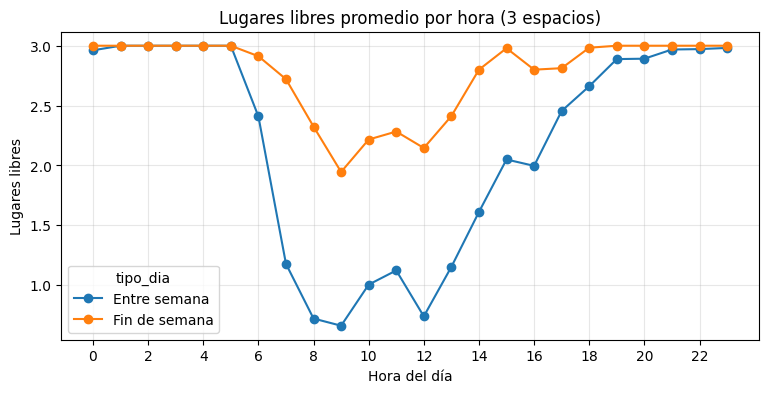

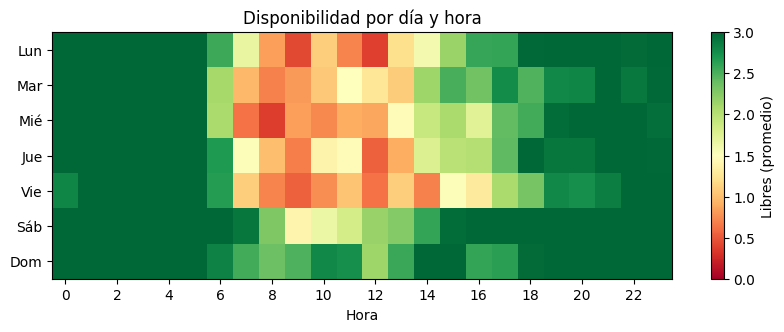

In [3]:
d = df.copy()
d["hora"] = d.index.hour
d["tipo_dia"] = np.where(d.index.dayofweek < 5, "Entre semana", "Fin de semana")
perfil = d.groupby(["tipo_dia", "hora"])["libres"].mean().unstack(0)

ax = perfil.plot(marker="o")
ax.set_title("Lugares libres promedio por hora (3 espacios)")
ax.set_xlabel("Hora del día"); ax.set_ylabel("Lugares libres")
ax.set_xticks(range(0, 24, 2)); plt.show()

mapa = d.groupby([d.index.dayofweek, "hora"])["libres"].mean().unstack()
plt.figure(figsize=(10, 3.2))
plt.imshow(mapa.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=N_CAJONES)
plt.colorbar(label="Libres (promedio)")
plt.yticks(range(7), ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"])
plt.xticks(range(0, 24, 2)); plt.xlabel("Hora"); plt.title("Disponibilidad por día y hora")
plt.grid(False); plt.show()

### 2.2 (Opcional) Datos reales del prototipo desde ThingSpeak
Cuando tu simulación en Wokwi ya haya enviado datos, pon `USAR_THINGSPEAK = True` en la celda de configuración y ejecuta esta celda.
Los campos del canal son: `field1..field3` = estado de cada espacio (1 = ocupado), `field4` = libres, `field5` = % de ocupación, `field6` = entradas acumuladas y `field7` = salidas acumuladas.

In [4]:
def leer_thingspeak(channel_id, read_key="", resultados=8000):
    url = f"https://api.thingspeak.com/channels/{channel_id}/feeds.csv?results={resultados}"
    if read_key: url += f"&api_key={read_key}"
    t = pd.read_csv(url)
    t["created_at"] = pd.to_datetime(t["created_at"], utc=True).dt.tz_convert("America/Tijuana").dt.tz_localize(None)
    t = t.set_index("created_at")
    nombres = {f"field{i+1}": f"espacio{i+1}" for i in range(N_CAJONES)}
    nombres.update({"field4": "libres", "field5": "ocupacion_pct", "field6": "entradas", "field7": "salidas"})
    return t.rename(columns=nombres)[list(nombres.values())].astype(float)

df_ts = None
if USAR_THINGSPEAK:
    df_ts = leer_thingspeak(TS_CHANNEL_ID, TS_READ_KEY)
    print(df_ts.shape)
    display(df_ts.tail())
    df_ts[["libres"]].plot(title="Lugares libres (datos reales del prototipo)", drawstyle="steps-post")
    plt.show()
else:
    print("USAR_THINGSPEAK = False: se omite la lectura (usa solo los datos sintéticos).")

USAR_THINGSPEAK = False: se omite la lectura (usa solo los datos sintéticos).


## 4. Variables y división cronológica
**Objetivo (y):** número de lugares libres dentro de `HORIZ_MIN` minutos (2 por defecto).
**Variables (X):** hora del día (seno/coseno para que 23:55 y 00:00 queden cerca), día de la semana, fin de semana, libres actuales, libres hace 1, 3 y 6 pasos (2, 6 y 12 min con el paso por defecto), tendencia de 3 pasos y promedio de 6 pasos.

La división es **cronológica** (los primeros días para entrenar y los últimos para probar), para no filtrar información del futuro al entrenamiento.

In [5]:
def construir_features(d, con_objetivo=True):
    x = pd.DataFrame(index=d.index)
    h = d.index.hour + d.index.minute / 60
    x["hora_sin"] = np.sin(2 * np.pi * h / 24)
    x["hora_cos"] = np.cos(2 * np.pi * h / 24)
    x["dia_semana"] = d.index.dayofweek
    x["fin_semana"] = (d.index.dayofweek >= 5).astype(int)
    x["libres_ahora"] = d["libres"]
    x["libres_1paso"]  = d["libres"].shift(1)
    x["libres_3pasos"] = d["libres"].shift(3)
    x["libres_6pasos"] = d["libres"].shift(6)
    x["tendencia_15"] = d["libres"] - d["libres"].shift(3)
    x["media_30min"]  = d["libres"].rolling(6).mean()
    if con_objetivo:
        x["y_libres_30"] = d["libres"].shift(-PASOS_H)
    return x

datos = construir_features(df).dropna()
FEATURES = [c for c in datos.columns if c != "y_libres_30"]

corte = int(len(datos) * 0.75)
train, test = datos.iloc[:corte], datos.iloc[corte:]
Xtr, ytr = train[FEATURES], train["y_libres_30"]
Xte, yte = test[FEATURES],  test["y_libres_30"]
print(f"Entrenamiento: {train.index[0]} a {train.index[-1]}  ({len(train)} filas)")
print(f"Prueba:        {test.index[0]} a {test.index[-1]}  ({len(test)} filas)")

Entrenamiento: 2026-09-07 00:12:00 a 2026-09-27 23:58:00  (15114 filas)
Prueba:        2026-09-28 00:00:00 a 2026-10-04 23:56:00  (5039 filas)


## 5. Modelos de regresión vs. línea base
La **línea base de persistencia** supone que dentro de `HORIZ_MIN` minutos habrá los mismos lugares libres que ahora. Un modelo solo se justifica si la supera en la prueba.

In [6]:
def metricas(y, p):
    return dict(R2=r2_score(y, p), RMSE=np.sqrt(mean_squared_error(y, p)), MAE=mean_absolute_error(y, p))

modelos = {
    "Regresión lineal": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=SEED),
}

filas, preds = [], {}
p_base = Xte["libres_ahora"].values
filas.append({"Modelo": "Línea base (persistencia)", **{f"{k} prueba": v for k, v in metricas(yte, p_base).items()},
              "R2 entrenamiento": r2_score(ytr, Xtr["libres_ahora"])})
preds["Línea base (persistencia)"] = p_base

for nombre, m in modelos.items():
    m.fit(Xtr, ytr)
    p = np.clip(m.predict(Xte), 0, N_CAJONES)
    preds[nombre] = p
    filas.append({"Modelo": nombre, **{f"{k} prueba": v for k, v in metricas(yte, p).items()},
                  "R2 entrenamiento": r2_score(ytr, np.clip(m.predict(Xtr), 0, N_CAJONES))})

resumen = pd.DataFrame(filas).set_index("Modelo").round(4)
resumen

,R2 prueba,RMSE prueba,MAE prueba,R2 entrenamiento
Modelo,,,,
Línea base (persistencia),0.9712,0.1748,0.0290,0.9692
Regresión lineal,0.9717,0.1736,0.0460,0.9698
Random Forest,0.9672,0.1866,0.0649,0.9773
Gradient Boosting,0.9707,0.1766,0.0576,0.9731


Mejor modelo: Regresión lineal
RMSE línea base = 0.175 | RMSE Regresión lineal = 0.174 | mejora = 0.7 %
-> El modelo NO mejora de forma apreciable a la línea base: bastaría con mostrar la disponibilidad actual.


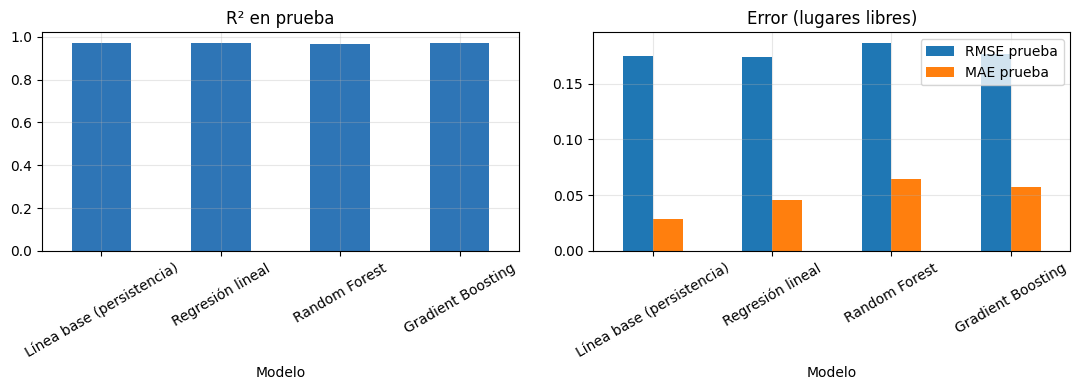

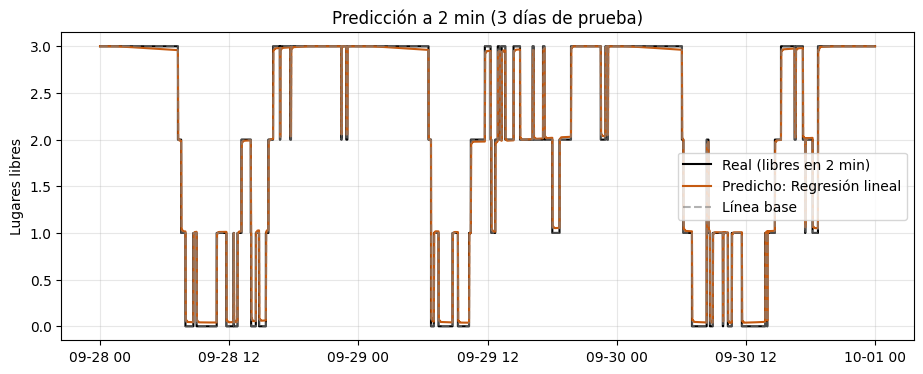

In [7]:
mejor = resumen.drop("Línea base (persistencia)")["RMSE prueba"].idxmin()
base_rmse = resumen.loc["Línea base (persistencia)", "RMSE prueba"]
mej_rmse = resumen.loc[mejor, "RMSE prueba"]
mejora = 100 * (base_rmse - mej_rmse) / base_rmse
print(f"Mejor modelo: {mejor}")
print(f"RMSE línea base = {base_rmse:.3f} | RMSE {mejor} = {mej_rmse:.3f} | mejora = {mejora:.1f} %")
if mejora > 5:
    print("-> El modelo SÍ supera a la línea base de forma apreciable (con estos datos sintéticos).")
else:
    print("-> El modelo NO mejora de forma apreciable a la línea base: bastaría con mostrar la disponibilidad actual.")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
resumen["R2 prueba"].plot.bar(ax=ax[0], color="#2e75b6"); ax[0].set_title("R² en prueba"); ax[0].tick_params(axis="x", rotation=30)
resumen[["RMSE prueba", "MAE prueba"]].plot.bar(ax=ax[1]); ax[1].set_title("Error (lugares libres)"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

# Un tramo de 3 días de la prueba
tramo = slice(0, 3 * 24 * 60 // PASO_MIN)
plt.figure(figsize=(11, 4))
plt.plot(yte.index[tramo], yte.values[tramo], label=f"Real (libres en {HORIZ_MIN} min)", color="black", drawstyle="steps-post")
plt.plot(yte.index[tramo], preds[mejor][tramo], label=f"Predicho: {mejor}", color="#c55a11")
plt.plot(yte.index[tramo], preds["Línea base (persistencia)"][tramo], label="Línea base", color="gray", alpha=.6, linestyle="--")
plt.legend(); plt.title(f"Predicción a {HORIZ_MIN} min (3 días de prueba)"); plt.ylabel("Lugares libres"); plt.show()

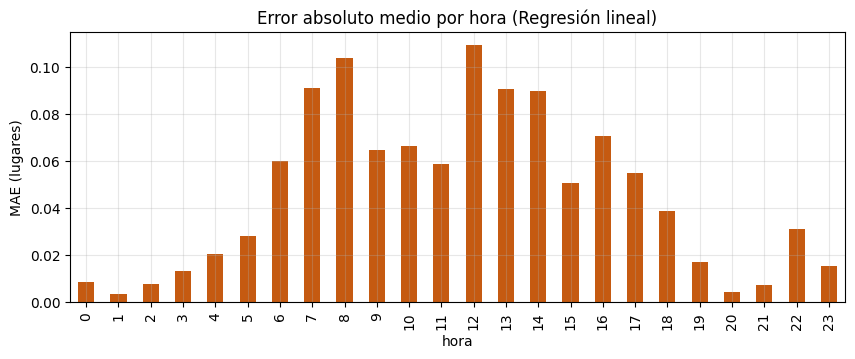

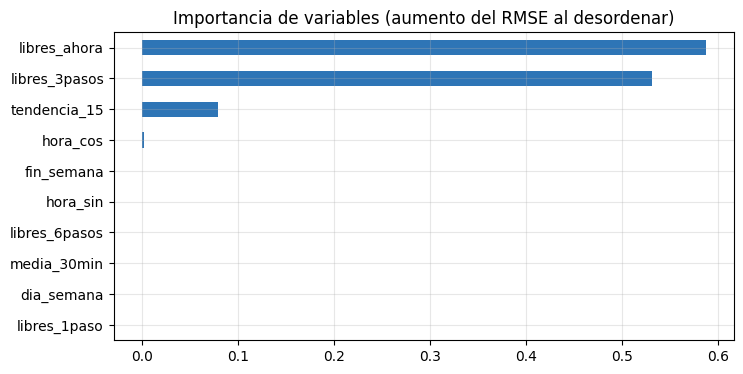

In [8]:
# Error por hora del día (mejor modelo)
err = pd.DataFrame({"hora": yte.index.hour, "abs": np.abs(yte.values - preds[mejor])})
err.groupby("hora")["abs"].mean().plot.bar(color="#c55a11", figsize=(10, 3.5))
plt.title(f"Error absoluto medio por hora ({mejor})"); plt.ylabel("MAE (lugares)"); plt.show()

# Importancia de variables (por permutación)
m = modelos[mejor]
imp = permutation_importance(m, Xte, yte, n_repeats=5, random_state=SEED, scoring="neg_root_mean_squared_error")
pd.Series(imp.importances_mean, index=FEATURES).sort_values().plot.barh(color="#2e75b6", figsize=(8, 4))
plt.title("Importancia de variables (aumento del RMSE al desordenar)"); plt.show()

### 5.1 ¿Cómo cambia el resultado según el horizonte de predicción?
Con un horizonte muy corto (2 min) casi nada cambia entre un registro y el siguiente, y la línea base de persistencia es muy difícil de superar. Esta tabla repite la comparación con distintos horizontes (con los mismos datos sintéticos) para ver **a partir de cuándo** el aprendizaje automático aporta algo.

,RMSE línea base,Mejor modelo,RMSE mejor modelo,Mejora (%)
Horizonte (min),,,,
2,0.175,Regresión lineal,0.174,0.717
10,0.367,Regresión lineal,0.357,2.909
20,0.507,Regresión lineal,0.477,5.820
30,0.597,Regresión lineal,0.548,8.195


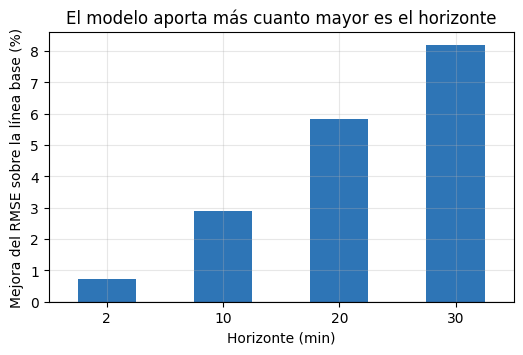

In [9]:
horizontes = [2, 10, 20, 30]      # minutos (múltiplos de PASO_MIN)
filas_h = []
feats_base = construir_features(df, con_objetivo=False)
for hmin in horizontes:
    pasos = hmin // PASO_MIN
    dd = feats_base.copy()
    dd["y"] = df["libres"].shift(-pasos)
    dd = dd.dropna()
    c = int(len(dd) * 0.75)
    Xa, ya, Xb, yb = dd.iloc[:c][FEATURES], dd.iloc[:c]["y"], dd.iloc[c:][FEATURES], dd.iloc[c:]["y"]
    rmse_base = np.sqrt(mean_squared_error(yb, Xb["libres_ahora"]))
    mejores = {}
    for nombre, m in {"Regresión lineal": make_pipeline(StandardScaler(), LinearRegression()),
                      "Gradient Boosting": HistGradientBoostingRegressor(random_state=SEED)}.items():
        m.fit(Xa, ya)
        mejores[nombre] = np.sqrt(mean_squared_error(yb, np.clip(m.predict(Xb), 0, N_CAJONES)))
    mejor_n = min(mejores, key=mejores.get)
    filas_h.append({"Horizonte (min)": hmin, "RMSE línea base": rmse_base,
                    "Mejor modelo": mejor_n, "RMSE mejor modelo": mejores[mejor_n],
                    "Mejora (%)": 100 * (rmse_base - mejores[mejor_n]) / rmse_base})
tabla_h = pd.DataFrame(filas_h).set_index("Horizonte (min)").round(3)
display(tabla_h)

ax = tabla_h["Mejora (%)"].plot.bar(color="#2e75b6", figsize=(6, 3.5))
ax.axhline(0, color="black", lw=.8); ax.set_ylabel("Mejora del RMSE sobre la línea base (%)")
ax.set_title("El modelo aporta más cuanto mayor es el horizonte"); plt.xticks(rotation=0); plt.show()

## 6. Clasificación del estado de la zona (opcional)
Con 3 espacios, el porcentaje de ocupación solo toma los valores 0, 33, 67 y 100 %. Las categorías coinciden con los LEDs del prototipo:

* **Disponible** (LED verde): 2 o más lugares libres
* **Casi llena** (LED amarillo): 1 lugar libre
* **Llena** (LED rojo): 0 lugares libres

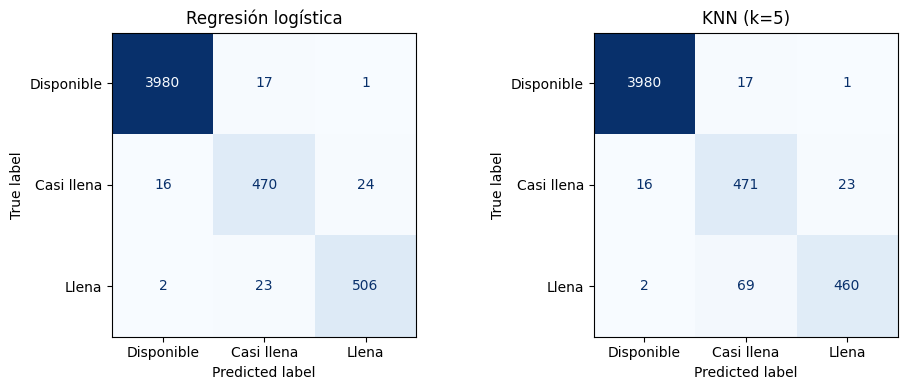

,Exactitud,F1 macro
Modelo,,
Línea base (persistencia),0.9835,0.9567
Regresión logística,0.9835,0.9567
KNN (k=5),0.9746,0.9283


In [10]:
ytr_c, yte_c = estado(ytr.values), estado(yte.values)
clases = ["Disponible", "Casi llena", "Llena"]
clasif = {
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
base_c = estado(Xte["libres_ahora"].values)
filas_c = [{"Modelo": "Línea base (persistencia)", "Exactitud": accuracy_score(yte_c, base_c),
            "F1 macro": f1_score(yte_c, base_c, average="macro")}]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for k, (nombre, m) in enumerate(clasif.items()):
    m.fit(Xtr, ytr_c); p = m.predict(Xte)
    filas_c.append({"Modelo": nombre, "Exactitud": accuracy_score(yte_c, p), "F1 macro": f1_score(yte_c, p, average="macro")})
    ConfusionMatrixDisplay.from_predictions(yte_c, p, labels=clases, ax=ax[k], colorbar=False, cmap="Blues")
    ax[k].set_title(nombre); ax[k].grid(False)
plt.tight_layout(); plt.show()
pd.DataFrame(filas_c).set_index("Modelo").round(4)

## 7. Predicción con el último dato real del prototipo (ThingSpeak)
Se remuestrea el canal a intervalos de 5 minutos, se calculan las **mismas variables** y se usa el mejor modelo regresor.
Necesita al menos unos 15 minutos de datos reales en el canal (unos 8 registros, porque el prototipo envía uno cada 2 minutos).

In [11]:
if df_ts is None or len(df_ts) == 0:
    print("Sin datos de ThingSpeak: activa USAR_THINGSPEAK en la configuración y vuelve a ejecutar desde la sección 2.2.")
else:
    real = df_ts[["libres"]].resample(f"{PASO_MIN}min").last().ffill()
    f = construir_features(real, con_objetivo=False).dropna()
    if len(f) == 0:
        print("Aún no hay suficiente historia (se necesitan ~15 min de datos reales).")
    else:
        ultimo = f.iloc[[-1]][FEATURES]
        pred = float(np.clip(modelos[mejor].predict(ultimo)[0], 0, N_CAJONES))
        print(f"Registro más reciente: {ultimo.index[0]}")
        print(f"Libres ahora: {int(ultimo['libres_ahora'].iloc[0])}")
        print(f"Predicción de libres en {HORIZ_MIN} min ({mejor}): {pred:.1f}  -> estado esperado: {estado(np.array([round(pred)]))[0]}")
        print("Nota: el modelo se entrenó con datos sintéticos; esta predicción es una demostración del flujo completo.")

Sin datos de ThingSpeak: activa USAR_THINGSPEAK en la configuración y vuelve a ejecutar desde la sección 2.2.


## 8. Resumen para el reporte
* Tabla de la sección 5: R², RMSE y MAE de cada modelo y de la línea base.
* ¿El mejor modelo supera a la línea base? (ver mensaje de la sección 5).
* Limitaciones: datos sintéticos, una sola zona de 3 espacios, una sola división de datos y modelos con hiperparámetros por defecto. Con 3 espacios la variable objetivo solo toma valores enteros de 0 a 3, lo que limita el R².
* Siguiente paso: reemplazar los datos sintéticos por datos medidos en el estacionamiento físico.